In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

np.random.seed(7)
dates = pd.date_range("2025-01-01", "2025-12-31", freq="D")
cities = ["Delhi", "Mumbai", "Bengaluru"]
categories = ["Electronics", "Clothing", "Grocery"]

df = pd.DataFrame(
    [(d, c, k) for d in dates for c in cities for k in categories],
    columns=["Date", "City", "Category"],
)
base = {"Electronics": 400, "Clothing": 250, "Grocery": 150}
n = len(df)

df["Discount"] = np.random.choice([0, 5, 10, 15, 20], n)
trend = 1 + df["Date"].dt.dayofyear / 365 * 0.3
weekend = np.where(df["Date"].dt.dayofweek >= 5, 1.25, 1.0)
festive = np.where(df["Date"].dt.month.isin([10, 11]), 1.3, 1.0)
city_factor = df["City"].map({"Delhi": 1.0, "Mumbai": 1.15, "Bengaluru": 0.9})

df["Revenue"] = (df["Category"].map(base) * trend * weekend * festive * city_factor
                 * (1 + df["Discount"] / 100) * np.random.normal(1, 0.08, n)).round(1)

# a few unusual values for you to find
df.loc[[100, 1502, 2801], "Revenue"] *= 8

df.head()


,Date,City,Category,Discount,Revenue
0,2025-01-01,Delhi,Electronics,20,427.1
1,2025-01-01,Delhi,Clothing,5,223.7
2,2025-01-01,Delhi,Grocery,15,143.1
3,2025-01-01,Mumbai,Electronics,15,512.0
4,2025-01-01,Mumbai,Clothing,20,409.8


In [5]:
df.info()

display(df.describe())

print("Missing values:")
print(df.isnull().sum())

print("\nNumber of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("Start date:", df["Date"].min())
print("End date:", df["Date"].max())

df["Month"] = df["Date"].dt.month
df["Weekday"] = df["Date"].dt.dayofweek

display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 3285 entries, 0 to 3284
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      3285 non-null   datetime64[us]
 1   City      3285 non-null   str           
 2   Category  3285 non-null   str           
 3   Discount  3285 non-null   int64         
 4   Revenue   3285 non-null   float64       
 5   Month     3285 non-null   int32         
 6   Weekday   3285 non-null   int32         
dtypes: datetime64[us](1), float64(1), int32(2), int64(1), str(2)
memory usage: 154.1 KB


,Date,Discount,Revenue,Month,Weekday
count,3285,3285.000000,3285.000000,3285.000000,3285.000000
mean,2025-07-02 00:00:00,9.785388,388.562466,6.526027,2.997260
min,2025-01-01 00:00:00,0.000000,122.300000,1.000000,0.000000
25%,2025-04-02 00:00:00,5.000000,238.400000,4.000000,1.000000
50%,2025-07-02 00:00:00,10.000000,350.800000,7.000000,3.000000
75%,2025-10-01 00:00:00,15.000000,501.500000,10.000000,5.000000
max,2025-12-31 00:00:00,20.000000,2883.200000,12.000000,6.000000
std,NaN,7.041371,191.995472,3.448376,1.998246


Missing values:
Date        0
City        0
Category    0
Discount    0
Revenue     0
Month       0
Weekday     0
dtype: int64

Number of rows: 3285
Number of columns: 7
Start date: 2025-01-01 00:00:00
End date: 2025-12-31 00:00:00


,Date,City,Category,Discount,Revenue,Month,Weekday
0,2025-01-01,Delhi,Electronics,20,427.1,1,2
1,2025-01-01,Delhi,Clothing,5,223.7,1,2
2,2025-01-01,Delhi,Grocery,15,143.1,1,2
3,2025-01-01,Mumbai,Electronics,15,512.0,1,2
4,2025-01-01,Mumbai,Clothing,20,409.8,1,2


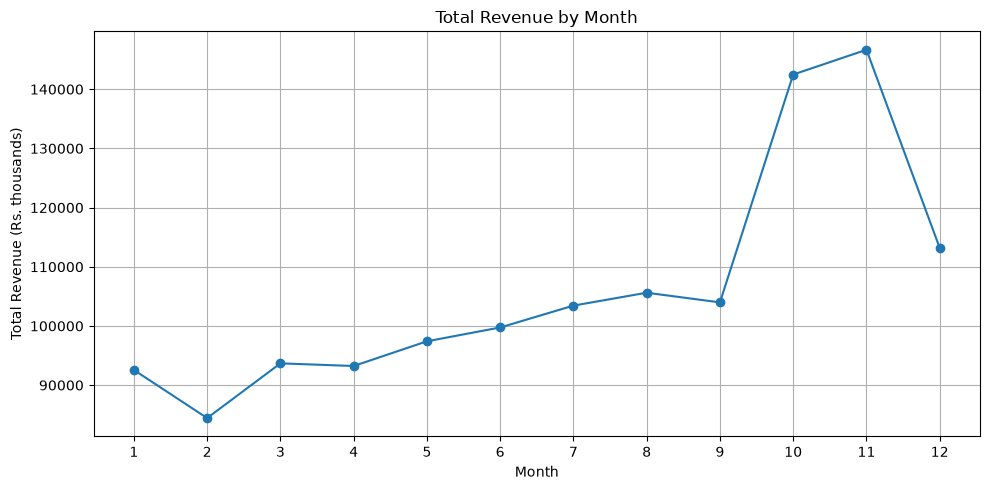

Highest revenue month: November
Highest revenue: 146668.1
Lowest revenue month: February
Lowest revenue: 84433.7


In [6]:
#Task 2
monthly_revenue = df.groupby("Month")["Revenue"].sum()

plt.figure(figsize=(10, 5))
plt.plot(monthly_revenue.index, monthly_revenue.values, marker="o")

plt.title("Total Revenue by Month")
plt.xlabel("Month")
plt.ylabel("Total Revenue (Rs. thousands)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

highest_month = monthly_revenue.idxmax()
lowest_month = monthly_revenue.idxmin()

month_names = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

print("Highest revenue month:", month_names[highest_month - 1])
print("Highest revenue:", round(monthly_revenue.max(), 2))

print("Lowest revenue month:", month_names[lowest_month - 1])
print("Lowest revenue:", round(monthly_revenue.min(), 2))

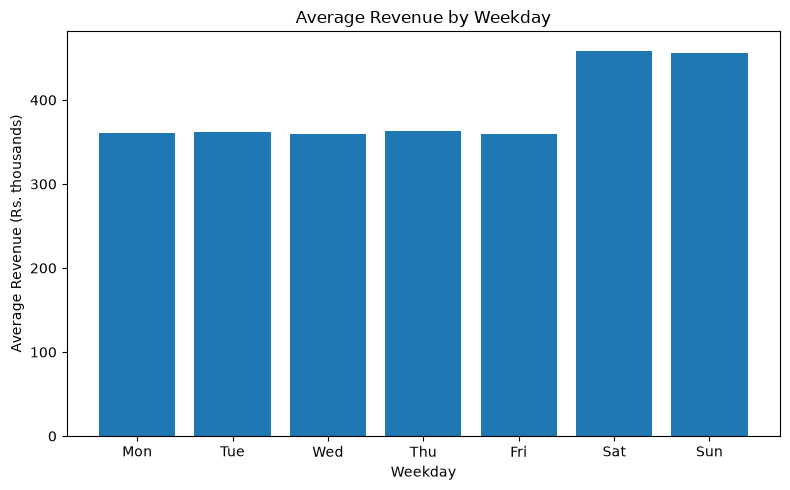

Highest average revenue day: Saturday
Lowest average revenue day: Wednesday
Difference in average revenue: 99.3


In [7]:
#Task 3
weekday_revenue = df.groupby("Weekday")["Revenue"].mean()

plt.figure(figsize=(8, 5))
plt.bar(weekday_revenue.index, weekday_revenue.values)

plt.title("Average Revenue by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Revenue (Rs. thousands)")
plt.xticks(
    range(7),
    ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
)

plt.tight_layout()
plt.show()

highest_day = weekday_revenue.idxmax()
lowest_day = weekday_revenue.idxmin()

day_names = ["Monday", "Tuesday", "Wednesday",
             "Thursday", "Friday", "Saturday", "Sunday"]

print("Highest average revenue day:", day_names[highest_day])
print("Lowest average revenue day:", day_names[lowest_day])

print("Difference in average revenue:",
      round(weekday_revenue.max() - weekday_revenue.min(), 2))

Category,Clothing,Electronics,Grocery
City,,,
Bengaluru,320.24,518.33,194.47
Delhi,360.09,570.02,220.16
Mumbai,408.54,658.99,246.22


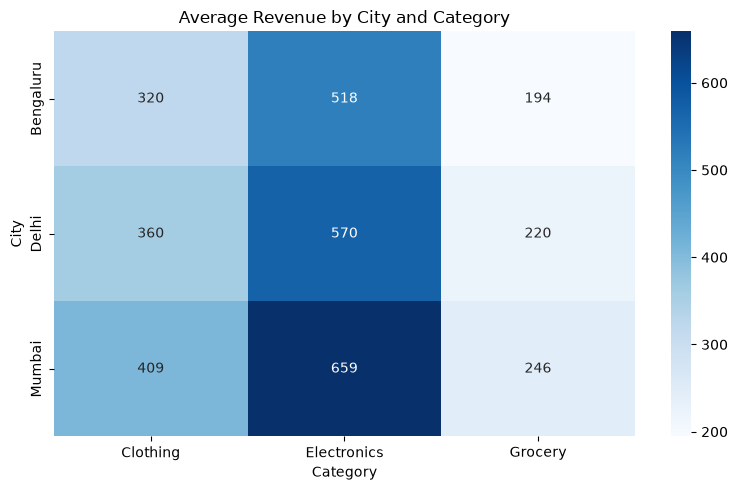

Best-performing city: Mumbai
Average revenue: 437.92

Highest-revenue category in each city:
City
Bengaluru    Electronics
Delhi        Electronics
Mumbai       Electronics
dtype: str


In [8]:
#Task 4
pv = df.pivot_table(
    index="City",
    columns="Category",
    values="Revenue",
    aggfunc="mean"
)

display(pv.round(2))

plt.figure(figsize=(8, 5))
sns.heatmap(pv, annot=True, fmt=".0f", cmap="Blues")

plt.title("Average Revenue by City and Category")
plt.xlabel("Category")
plt.ylabel("City")
plt.tight_layout()
plt.show()

city_average = df.groupby("City")["Revenue"].mean()
print("Best-performing city:", city_average.idxmax())
print("Average revenue:", round(city_average.max(), 2))

print("\nHighest-revenue category in each city:")
print(pv.idxmax(axis=1))

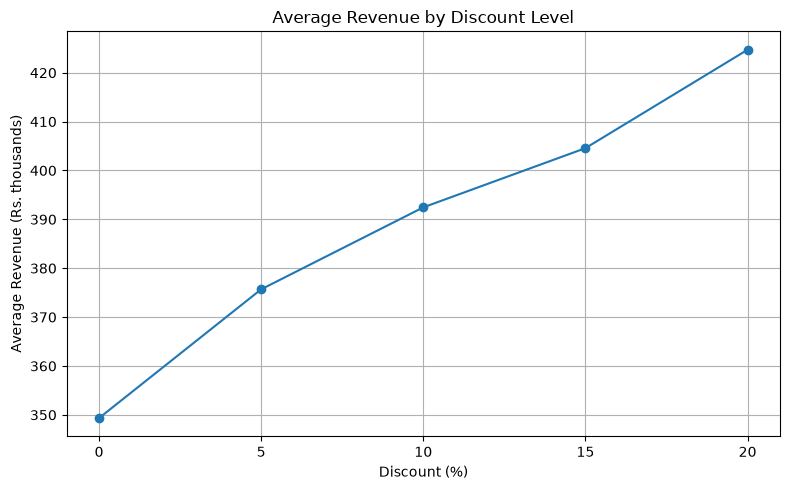

Discount
0     349.34
5     375.68
10    392.46
15    404.57
20    424.70
Name: Revenue, dtype: float64

In [9]:
#Task 5
discount_revenue = df.groupby("Discount")["Revenue"].mean()

plt.figure(figsize=(8, 5))
plt.plot(discount_revenue.index, discount_revenue.values, marker="o")

plt.title("Average Revenue by Discount Level")
plt.xlabel("Discount (%)")
plt.ylabel("Average Revenue (Rs. thousands)")
plt.xticks(sorted(df["Discount"].unique()))
plt.grid(True)
plt.tight_layout()
plt.show()

display(discount_revenue.round(2))

In [ ]:
#Task 6
fig = px.box(
    df,
    x="Category",
    y="Revenue",
    hover_data=["Date", "City"],
    title="Revenue Distribution and Outliers by Category"
)

fig.update_layout(
    xaxis_title="Category",
    yaxis_title="Revenue (Rs. thousands)"
)

fig.show()

In [11]:
outliers = df.nlargest(3, "Revenue")[
    ["Date", "City", "Category", "Revenue"]
].sort_values("Revenue", ascending=False)

display(outliers)

,Date,City,Category,Revenue
100,2025-01-12,Delhi,Clothing,2883.2
2801,2025-11-08,Delhi,Grocery,2779.2
2811,2025-11-09,Mumbai,Electronics,1288.5


In [12]:
category_mean = df.groupby("Category")["Revenue"].transform("mean")

clean = df[df["Revenue"] <= 3 * category_mean].copy()

removed_rows = len(df) - len(clean)

print("Original number of rows:", len(df))
print("Rows after removing outliers:", len(clean))
print("Number of rows removed:", removed_rows)

assert removed_rows == 3, "Check the outlier-removal result."

Original number of rows: 3285
Rows after removing outliers: 3282
Number of rows removed: 3


In [13]:
#Task 7
monthly = clean.groupby(
    ["Month", "City"], as_index=False
)["Revenue"].sum()

fig_a = px.line(
    monthly,
    x="Month",
    y="Revenue",
    color="City",
    markers=True,
    title="Monthly Revenue by City"
)

fig_a.update_layout(
    xaxis_title="Month",
    yaxis_title="Total Revenue (Rs. thousands)",
    xaxis=dict(tickmode="linear", dtick=1)
)

fig_a.show()

In [14]:
category_revenue = clean.groupby(
    "Category", as_index=False
)["Revenue"].sum()

fig_b = px.bar(
    category_revenue,
    x="Category",
    y="Revenue",
    title="Total Revenue by Category"
)

fig_b.update_layout(
    xaxis_title="Category",
    yaxis_title="Total Revenue (Rs. thousands)"
)

fig_b.show()

In [15]:
pv_clean = clean.pivot_table(
    index="City",
    columns="Category",
    values="Revenue",
    aggfunc="mean"
)

fig_c = px.imshow(
    pv_clean,
    text_auto=".0f",
    color_continuous_scale="Blues",
    title="Average Revenue: City vs Category",
    labels={
        "x": "Category",
        "y": "City",
        "color": "Average Revenue"
    }
)

fig_c.show()

In [17]:
discount_clean = clean.groupby(
    "Discount", as_index=False
)["Revenue"].mean()

fig_d = px.bar(
    discount_clean,
    x="Discount",
    y="Revenue",
    title="Average Revenue by Discount (%)"
)

fig_d.update_layout(
    xaxis_title="Discount (%)",
    yaxis_title="Average Revenue (Rs. thousands)"
)

fig_d.show()

In [18]:
#Task 8
from plotly.subplots import make_subplots
import plotly.graph_objects as go

dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Monthly Revenue by City",
        "Total Revenue by Category",
        "Average Revenue: City vs Category",
        "Average Revenue by Discount (%)"
    ),
    specs=[
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "heatmap"}, {"type": "xy"}]
    ]
)

# Add Chart A
for trace in fig_a.data:
    dash.add_trace(trace, row=1, col=1)

# Add Chart B
for trace in fig_b.data:
    dash.add_trace(trace, row=1, col=2)

# Add Chart C
for trace in fig_c.data:
    dash.add_trace(trace, row=2, col=1)

# Add Chart D
for trace in fig_d.data:
    dash.add_trace(trace, row=2, col=2)

# Axis titles
dash.update_xaxes(title_text="Month", row=1, col=1)
dash.update_yaxes(title_text="Revenue (Rs. thousands)", row=1, col=1)

dash.update_xaxes(title_text="Category", row=1, col=2)
dash.update_yaxes(title_text="Revenue (Rs. thousands)", row=1, col=2)

dash.update_xaxes(title_text="Category", row=2, col=1)
dash.update_yaxes(title_text="City", row=2, col=1)

dash.update_xaxes(title_text="Discount (%)", row=2, col=2)
dash.update_yaxes(title_text="Average Revenue (Rs. thousands)", row=2, col=2)

dash.update_coloraxes(showscale=False)

dash.update_layout(
    height=700,
    title_text="Retail Sales Dashboard",
    template="simple_white"
)

dash.show()

# Save the dashboard as an HTML file
dash.write_html("sales_dashboard.html")

print("Dashboard saved as sales_dashboard.html")

Dashboard saved as sales_dashboard.html


In [19]:
#Task 9
# Finding 1: Highest-revenue month
monthly_clean = clean.groupby("Month")["Revenue"].sum()

highest_month = monthly_clean.idxmax()
lowest_month = monthly_clean.idxmin()

month_names = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

print("Highest-revenue month:", month_names[highest_month - 1])
print("Revenue:", round(monthly_clean.max(), 2))

print("\nLowest-revenue month:", month_names[lowest_month - 1])
print("Revenue:", round(monthly_clean.min(), 2))


# Finding 2: Best-performing city
city_revenue = clean.groupby("City")["Revenue"].sum()

print("\nHighest-revenue city:", city_revenue.idxmax())
print("Total revenue:", round(city_revenue.max(), 2))


# Finding 3: Best-performing category
category_revenue = clean.groupby("Category")["Revenue"].sum()

print("\nHighest-revenue category:", category_revenue.idxmax())
print("Total revenue:", round(category_revenue.max(), 2))


# Data quality
print("\nOriginal rows:", len(df))
print("Cleaned rows:", len(clean))
print("Rows removed:", len(df) - len(clean))

Highest-revenue month: November
Revenue: 143888.9

Lowest-revenue month: February
Revenue: 84433.7

Highest-revenue city: Mumbai
Total revenue: 479519.9

Highest-revenue category: Electronics
Total revenue: 637778.3

Original rows: 3285
Cleaned rows: 3282
Rows removed: 3


# Retail Sales Analysis Report

### Purpose
This report analyses retail sales across Delhi, Mumbai and Bengaluru during 2025 to identify revenue trends and useful business opportunities.

### Three Key Findings
1. **Monthly trend:** [Month] recorded the highest total revenue of approximately Rs. [value] thousand, while [month] recorded the lowest.
2. **City performance:** [City] generated the highest total revenue, approximately Rs. [value] thousand, among the three cities.
3. **Category performance:** [Category] generated the highest total revenue, approximately Rs. [value] thousand, among the three product categories.

### Data Quality Note
Three unusually high revenue values were identified and removed using the category-based threshold specified in the assignment. The other values were retained for analysis.

### Recommendations
1. Use monthly and city-level revenue patterns to plan inventory and allocate resources during periods of high demand.
2. Compare category performance and discount-level revenue before deciding which products and discount offers to prioritise.